<a href="https://colab.research.google.com/github/andrelison/salesinsight-py2/blob/feat%2Fpipeline-dados/salesinsigth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importar bibliotecas

In [1]:
import json
import os
import random
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

GERAR DATASET

In [2]:
def gerar_dataset_vendas(n_registros=200, seed=42):
    """Gera um dataset sintetico de vendas com dados sujos."""
    random.seed(seed)
    np.random.seed(seed)

    produtos = ["Notebook", "Smartphone", "Tablet", "Monitor",
                "Teclado", "Mouse", "Headset"]
    categorias = {"Notebook": "Computadores", "Smartphone": "Celulares",
                  "Tablet": "Celulares", "Monitor": "Computadores",
                  "Teclado": "Perifericos", "Mouse": "Perifericos",
                  "Headset": "Perifericos"}
    precos = {"Notebook": 3500, "Smartphone": 2200, "Tablet": 1800,
              "Monitor": 1200, "Teclado": 250, "Mouse": 120,
              "Headset": 350}
    regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]

    data_inicio = datetime(2025, 1, 1)
    dados = []

    for i in range(n_registros):
        produto = random.choice(produtos)
        categoria = categorias[produto]
        quantidade = random.randint(1, 10)
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)
        data = data_inicio + timedelta(days=random.randint(0, 364))
        data_txt = data.strftime("%Y-%m-%d")
        cliente = f"Cliente_{random.randint(1, 50):03d}"

        # --- sujeira proposital para a etapa de limpeza ---
        if random.random() < 0.03:
            data_txt = "DATA INVALIDA"

        dados.append({
            "id_venda": i + 1,
            "data_venda": data_txt,
            "cliente": cliente,
            "produto": produto,
            "categoria": categoria,
            "regiao": random.choice(regioes),
            "quantidade": quantidade,
            "preco_unitario": preco,
        })

    return pd.DataFrame(dados)

df_bruto = gerar_dataset_vendas()
df_bruto.to_csv("vendas.csv", index=False)
print(f"Dataset gerado com {len(df_bruto)} registros.")

Dataset gerado com 200 registros.


INSPEÇÃO DE DADOS

In [3]:
def inspecionar_dados(df):
    """Exibe as informacoes estruturais do DataFrame."""
    print("\n=== INSPECAO INICIAL DO DATASET ===")
    print(f"Shape: {df.shape}")
    print(f"\nColunas: {list(df.columns)}")
    print(f"\nTipos de dados:\n{df.dtypes}")
    print(f"\nValores nulos por coluna:\n{df.isnull().sum()}")
    print(f"\nPrimeiros registros:\n{df.head()}")
    return df

inspecionar_dados(df_bruto)


=== INSPECAO INICIAL DO DATASET ===
Shape: (200, 8)

Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3         4     2025-05-23  Cliente_001     Monitor  Com

,id_venda,data_venda,cliente,produto,categoria,regiao,quantidade,preco_unitario
0,1,2025-05-21,Cliente_016,Mouse,Perifericos,Sudeste,2,102.90
1,2,DATA INVALIDA,Cliente_003,Mouse,Perifericos,Sul,9,105.13
2,3,2025-10-15,Cliente_013,Smartphone,Celulares,Norte,9,2267.33
3,4,2025-05-23,Cliente_001,Monitor,Computadores,Sul,4,1181.72
4,5,2025-03-21,Cliente_014,Mouse,Perifericos,Nordeste,7,114.25
...,...,...,...,...,...,...,...,...
195,196,2025-04-21,Cliente_028,Headset,Perifericos,Sul,9,373.19
196,197,2025-07-24,Cliente_027,Monitor,Computadores,Nordeste,6,1317.87
197,198,2025-07-11,Cliente_010,Monitor,Computadores,Centro-Oeste,6,1259.44
198,199,2025-02-17,Cliente_028,Notebook,Computadores,Nordeste,2,3848.36


ESQUELETO DA CLASSE

In [23]:
class AnalisadorDeVendas:
    """Organiza o fluxo: carregar, transformar, analisar, visualizar."""

    def __init__(self):
        self.df_bruto = None
        self.df = None
        self.relatorio_limpeza = None
        self.metricas = None
        self.clientes = None

    def carregar(self, caminho):
        """Le o CSV de vendas."""
        self.df_bruto = pd.read_csv(caminho)
        return self.df_bruto

    def transformar(self):
        """Limpa os dados e cria as colunas derivadas (RF03 e RF04)."""
        if self.df_bruto is None:
            raise ValueError("Carregue primeiro o dataset com carregar().")
        df_limpo, self.relatorio_limpeza = tratar_dados(self.df_bruto)
        self.df = criar_colunas_derivadas(df_limpo)
        return self.df

    def analisar(self):
        """Calcula as metricas agregadas e segmenta os clientes (RF05 e RF06)."""
        if self.df is None:
            raise ValueError("Execute transformar() antes de analisar().")
        self.metricas = calcular_metricas(self.df)
        exibir_metricas(self.metricas)
        self.clientes = segmentar_clientes(self.df)
        exibir_segmentacao(self.clientes)
        return self.metricas

    def visualizar(self, pasta="outputs/graficos"):
        """Gera e salva os 4 graficos (RF07)."""
        if self.metricas is None:
            raise ValueError("Execute analisar() antes de visualizar().")
        return gerar_graficos(self.df, self.metricas, pasta)

impeza dos dados

In [5]:
def tratar_dados(df):
    """
    Trata o DataFrame de vendas (RF03).
    Retorna: (df_limpo, relatorio), onde relatorio e um dicionario
    com as contagens de registros iniciais, convertidos e finais.
    """
    df = df.copy()
    antes = df.copy()                      # copia para comparar depois
    registros_iniciais = len(df)

    # 1. remover espacos extras nas colunas de texto
    colunas_texto = df.select_dtypes(include="object").columns
    for col in colunas_texto:
        df[col] = df[col].str.strip()
    # True nas linhas em que algum texto mudou depois do strip
    mudou_texto = (
        antes[colunas_texto].fillna("") != df[colunas_texto].fillna("")
    ).any(axis=1)

    # 2. converter data_venda e descartar datas invalidas
    df["data_venda"] = pd.to_datetime(df["data_venda"], errors="coerce")
    datas_invalidas = int(df["data_venda"].isna().sum())
    df = df[df["data_venda"].notna()].copy()
    datas_convertidas = len(df)

    # 3. ajustar tipos numericos
    tipos_ajustados = 0
    for coluna, tipo in {"quantidade": int, "preco_unitario": float}.items():
        convertida = df[coluna].astype(tipo)
        if convertida.dtype != antes[coluna].dtype:
            tipos_ajustados += 1
        df[coluna] = convertida

    # 4. montar e imprimir o relatorio de limpeza
    # "sem alteracao" = linhas cujo texto e tipos numericos nao mudaram
    if tipos_ajustados == 0:
        sem_alteracao = int((~mudou_texto.loc[df.index]).sum())
    else:
        sem_alteracao = 0

    relatorio = {
        "registros_iniciais": registros_iniciais,
        "espacos_removidos (linhas)": int(mudou_texto.sum()),
        "datas_convertidas (texto -> datetime)": datas_convertidas,
        "datas_invalidas_removidas": datas_invalidas,
        "colunas_numericas_ajustadas": tipos_ajustados,
        "registros_sem_alteracao": sem_alteracao,
        "registros_finais": len(df),
    }

    print("\n=== RELATORIO DE LIMPEZA ===")
    for chave, valor in relatorio.items():
        print(f"  {chave}: {valor}")

    return df.reset_index(drop=True), relatorio

In [12]:
MESES_PT = {
    1: "Janeiro", 2: "Fevereiro", 3: "Marco", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro",
}

def criar_colunas_derivadas(df):
    """Cria as colunas derivadas exigidas no RF04."""
    df = df.copy()

    df["receita_total"] = df["quantidade"] * df["preco_unitario"]
    df["mes"] = df["data_venda"].dt.month
    df["mes_nome"] = df["mes"].map(MESES_PT)
    df["trimestre"] = "Q" + df["data_venda"].dt.quarter.astype(str)
    df["ano"] = df["data_venda"].dt.year

    condicoes = [
        df["receita_total"] < 500,
        (df["receita_total"] >= 500) & (df["receita_total"] < 5000),
        df["receita_total"] >= 5000,
    ]
    faixas = ["Baixo Valor", "Medio Valor", "Alto Valor"]
    df["faixa_receita_item"] = np.select(condicoes, faixas, default="Nao Classificado")

    return df

In [15]:
analisador = AnalisadorDeVendas()
analisador.carregar("vendas.csv")
analisador.transformar()
print(analisador.df.head())
print(analisador.df.dtypes)


=== RELATORIO DE LIMPEZA ===
  registros_iniciais: 200
  espacos_removidos (linhas): 0
  datas_convertidas (texto -> datetime): 194
  datas_invalidas_removidas: 6
  colunas_numericas_ajustadas: 0
  registros_sem_alteracao: 194
  registros_finais: 194
   id_venda data_venda      cliente     produto     categoria    regiao  \
0         1 2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         3 2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
2         4 2025-05-23  Cliente_001     Monitor  Computadores       Sul   
3         5 2025-03-21  Cliente_014       Mouse   Perifericos  Nordeste   
4         6 2025-07-03  Cliente_023    Notebook  Computadores   Sudeste   

   quantidade  preco_unitario  receita_total  mes mes_nome trimestre   ano  \
0           2          102.90         205.80    5     Maio        Q2  2025   
1           9         2267.33       20405.97   10  Outubro        Q4  2025   
2           4         1181.72        4726.88    5     Maio     

calcular_metricas

In [16]:
def calcular_metricas(df):
    """
    Calcula as metricas agregadas do dataset (RF05).
    Retorna um dicionario no formato {nome_da_metrica: DataFrame}.
    Chaves: por_mes, top_produtos, por_categoria, por_regiao.
    """
    metricas = {}

    # receita, quantidade e numero de vendas por mes
    metricas["por_mes"] = (
        df.groupby("mes")
        .agg(
            receita_total=("receita_total", "sum"),
            quantidade=("quantidade", "sum"),
            n_vendas=("id_venda", "count"),
        )
        .reset_index()
        .sort_values("mes")
    )

    # Top 5 produtos por receita, em ordem decrescente
    metricas["top_produtos"] = (
        df.groupby("produto")["receita_total"].sum()
        .reset_index()
        .sort_values("receita_total", ascending=False)
        .head(5)
    )

    # receita total por categoria
    metricas["por_categoria"] = (
        df.groupby("categoria")["receita_total"].sum()
        .reset_index()
        .sort_values("receita_total", ascending=False)
    )

    # receita total e ticket medio por regiao
    metricas["por_regiao"] = (
        df.groupby("regiao")
        .agg(
            receita_total=("receita_total", "sum"),
            ticket_medio=("receita_total", "mean"),
        )
        .reset_index()
        .sort_values("receita_total", ascending=False)
    )

    return metricas

exibir_metricas

In [17]:
def exibir_metricas(metricas):
    """Imprime cada metrica com um titulo legivel."""
    titulos = {
        "por_mes": "POR MES",
        "top_produtos": "TOP 5 PRODUTOS",
        "por_categoria": "POR CATEGORIA",
        "por_regiao": "POR REGIAO",
    }
    for chave, tabela in metricas.items():
        print(f"\n=== {titulos.get(chave, chave.upper())} ===")
        print(tabela.round(2).to_string(index=False))

segmentar_clientes

In [18]:
def segmentar_clientes(df):
    """
    Agrupa por cliente, soma a receita e classifica em Bronze / Prata / Ouro (RF06).
    Retorna um DataFrame com: cliente, total_gasto, segmento.
    """
    clientes = (
        df.groupby("cliente")["receita_total"].sum()
        .reset_index()
        .rename(columns={"receita_total": "total_gasto"})
    )

    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda gasto: "Bronze" if gasto < 5000
        else ("Prata" if gasto <= 15000 else "Ouro")
    )

    return clientes.sort_values("total_gasto", ascending=False).reset_index(drop=True)

exibir_segmentacao

In [19]:
def exibir_segmentacao(clientes):
    """Mostra os 10 maiores clientes e a distribuicao por segmento."""
    print("\n=== TOP 10 CLIENTES ===")
    print(clientes.head(10).round(2).to_string(index=False))
    print("\n=== DISTRIBUICAO POR SEGMENTO ===")
    print(clientes["segmento"].value_counts())

analisar na classe

In [24]:
    def analisar(self):
        """Calcula as metricas agregadas e segmenta os clientes (RF05 e RF06)."""
        if self.df is None:
            raise ValueError("Execute transformar() antes de analisar().")
        self.metricas = calcular_metricas(self.df)
        exibir_metricas(self.metricas)
        self.clientes = segmentar_clientes(self.df)
        exibir_segmentacao(self.clientes)
        return self.metricas

        # Injetando o m	todo analisar na classe AnalisadorDeVendas
AnalisadorDeVendas.analisar = analisar

# Executando o fluxo completo
analisador = AnalisadorDeVendas()
analisador.carregar("vendas.csv")
analisador.transformar()
analisador.analisar()


=== RELATORIO DE LIMPEZA ===
  registros_iniciais: 200
  espacos_removidos (linhas): 0
  datas_convertidas (texto -> datetime): 194
  datas_invalidas_removidas: 6
  colunas_numericas_ajustadas: 0
  registros_sem_alteracao: 194
  registros_finais: 194

=== POR MES ===
 mes  receita_total  quantidade  n_vendas
   1      121707.77          86        15
   2      186065.22          84        18
   3      129138.46          87        19
   4       68247.67          85        14
   5      103600.61          75        12
   6       72067.26          73        16
   7      129427.58          97        19
   8      156072.31         107        19
   9       57509.42          77        14
  10      181878.41         137        25
  11       89645.62          86        15
  12       84849.98          41         8

=== TOP 5 PRODUTOS ===
   produto  receita_total
  Notebook      493242.63
Smartphone      343721.95
    Tablet      236519.71
   Monitor      205212.61
   Headset       48879.79

=== 

{'por_mes':     mes  receita_total  quantidade  n_vendas
 0     1      121707.77          86        15
 1     2      186065.22          84        18
 2     3      129138.46          87        19
 3     4       68247.67          85        14
 4     5      103600.61          75        12
 5     6       72067.26          73        16
 6     7      129427.58          97        19
 7     8      156072.31         107        19
 8     9       57509.42          77        14
 9    10      181878.41         137        25
 10   11       89645.62          86        15
 11   12       84849.98          41         8,
 'top_produtos':       produto  receita_total
 3    Notebook      493242.63
 4  Smartphone      343721.95
 5      Tablet      236519.71
 1     Monitor      205212.61
 0     Headset       48879.79,
 'por_categoria':       categoria  receita_total
 1  Computadores      698455.24
 0     Celulares      580241.66
 2   Perifericos      101513.41,
 'por_regiao':          regiao  receita_total  

graficos

In [25]:
from matplotlib.ticker import FuncFormatter

PALETA_CATEGORIAS = {"Computadores": "#1B4F72", "Celulares": "#E67E22", "Perifericos": "#27AE60"}
COR_PRINCIPAL = "#1B4F72"

def configurar_estilo():
    """Define o estilo visual global dos graficos."""
    sns.set_theme(style="whitegrid")
    plt.rcParams["figure.figsize"] = (12, 6)
    plt.rcParams["axes.titlesize"] = 14

def formatar_reais(ax, eixo="y"):
    """Formata os valores do eixo como 'R$ 100 mil'."""
    eixo_alvo = ax.yaxis if eixo == "y" else ax.xaxis
    eixo_alvo.set_major_formatter(FuncFormatter(lambda v, _: f"R$ {v/1000:.0f} mil"))

def desenhar_linha_mes(ax, por_mes):
    """Linha: receita total por mes."""
    ax.plot(por_mes["mes"], por_mes["receita_total"], marker="o",
            linewidth=2, color=COR_PRINCIPAL, label="Receita total")
    ax.set_title("Receita Total por Mes")
    ax.set_xlabel("Mes")
    ax.set_ylabel("Receita total (R$)")
    ax.set_xticks(por_mes["mes"])
    ax.set_xticklabels([MESES_PT[m][:3] for m in por_mes["mes"]])
    formatar_reais(ax)
    ax.legend(loc="upper right")

def desenhar_barras_produtos(ax, top_produtos):
    """Barras: Top 5 produtos por receita."""
    sns.barplot(data=top_produtos, y="produto", x="receita_total",
                hue="produto", palette="Blues_d", legend=False, ax=ax)
    ax.set_title("Top 5 Produtos por Receita")
    ax.set_xlabel("Receita total (R$)")
    ax.set_ylabel("Produto")
    formatar_reais(ax, eixo="x")

def desenhar_dispersao(ax, df):
    """Dispersao: quantidade x receita, colorido por categoria."""
    sns.scatterplot(data=df, x="quantidade", y="receita_total", hue="categoria",
                    palette=PALETA_CATEGORIAS, alpha=0.7, s=60, ax=ax)
    ax.set_title("Quantidade x Receita por Transacao")
    ax.set_xlabel("Quantidade vendida")
    ax.set_ylabel("Receita da transacao (R$)")
    ax.legend(title="Categoria")

def desenhar_receita_regiao(ax, por_regiao):
    """Barras: receita total por regiao."""
    ax.bar(por_regiao["regiao"], por_regiao["receita_total"],
           color="#5D6D7E", label="Receita total")
    ax.set_title("Receita Total por Regiao")
    ax.set_xlabel("Regiao")
    ax.set_ylabel("Receita total (R$)")
    ax.tick_params(axis="x", rotation=20)
    formatar_reais(ax)

def salvar_figura(fig, nome, pasta, dpi=150):
    """Ajusta o layout, salva em PNG e fecha a figura."""
    caminho = os.path.join(pasta, nome)
    fig.tight_layout()
    fig.savefig(caminho, dpi=dpi)
    plt.close(fig)
    return caminho

def gerar_graficos(df, metricas, pasta="outputs/graficos"):
    """Gera as 4 figuras do RF07 e retorna a lista de caminhos salvos."""
    configurar_estilo()
    os.makedirs(pasta, exist_ok=True)
    caminhos = []

    # 1. linha
    fig, ax = plt.subplots(figsize=(10, 5))
    desenhar_linha_mes(ax, metricas["por_mes"])
    caminhos.append(salvar_figura(fig, "receita_por_mes.png", pasta))

    # 2. barras
    fig, ax = plt.subplots(figsize=(10, 5))
    desenhar_barras_produtos(ax, metricas["top_produtos"])
    caminhos.append(salvar_figura(fig, "top_produtos.png", pasta))

    # 3. dispersao
    fig, ax = plt.subplots(figsize=(10, 6))
    desenhar_dispersao(ax, df)
    caminhos.append(salvar_figura(fig, "quantidade_vs_receita.png", pasta))

    # 4. painel 2x2
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    desenhar_linha_mes(axes[0, 0], metricas["por_mes"])
    desenhar_barras_produtos(axes[0, 1], metricas["top_produtos"])
    desenhar_dispersao(axes[1, 0], df)
    desenhar_receita_regiao(axes[1, 1], metricas["por_regiao"])
    fig.suptitle("SalesInsight PY - Painel Resumo", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(os.path.join(pasta, "painel_resumo.png"), dpi=150)
    plt.close(fig)
    caminhos.append(os.path.join(pasta, "painel_resumo.png"))

    return caminhos

teste

In [26]:
analisador = AnalisadorDeVendas()
analisador.carregar("vendas.csv")
analisador.transformar()
analisador.analisar()
caminhos = analisador.visualizar()
print(caminhos)


=== RELATORIO DE LIMPEZA ===
  registros_iniciais: 200
  espacos_removidos (linhas): 0
  datas_convertidas (texto -> datetime): 194
  datas_invalidas_removidas: 6
  colunas_numericas_ajustadas: 0
  registros_sem_alteracao: 194
  registros_finais: 194

=== POR MES ===
 mes  receita_total  quantidade  n_vendas
   1      121707.77          86        15
   2      186065.22          84        18
   3      129138.46          87        19
   4       68247.67          85        14
   5      103600.61          75        12
   6       72067.26          73        16
   7      129427.58          97        19
   8      156072.31         107        19
   9       57509.42          77        14
  10      181878.41         137        25
  11       89645.62          86        15
  12       84849.98          41         8

=== TOP 5 PRODUTOS ===
   produto  receita_total
  Notebook      493242.63
Smartphone      343721.95
    Tablet      236519.71
   Monitor      205212.61
   Headset       48879.79

=== 

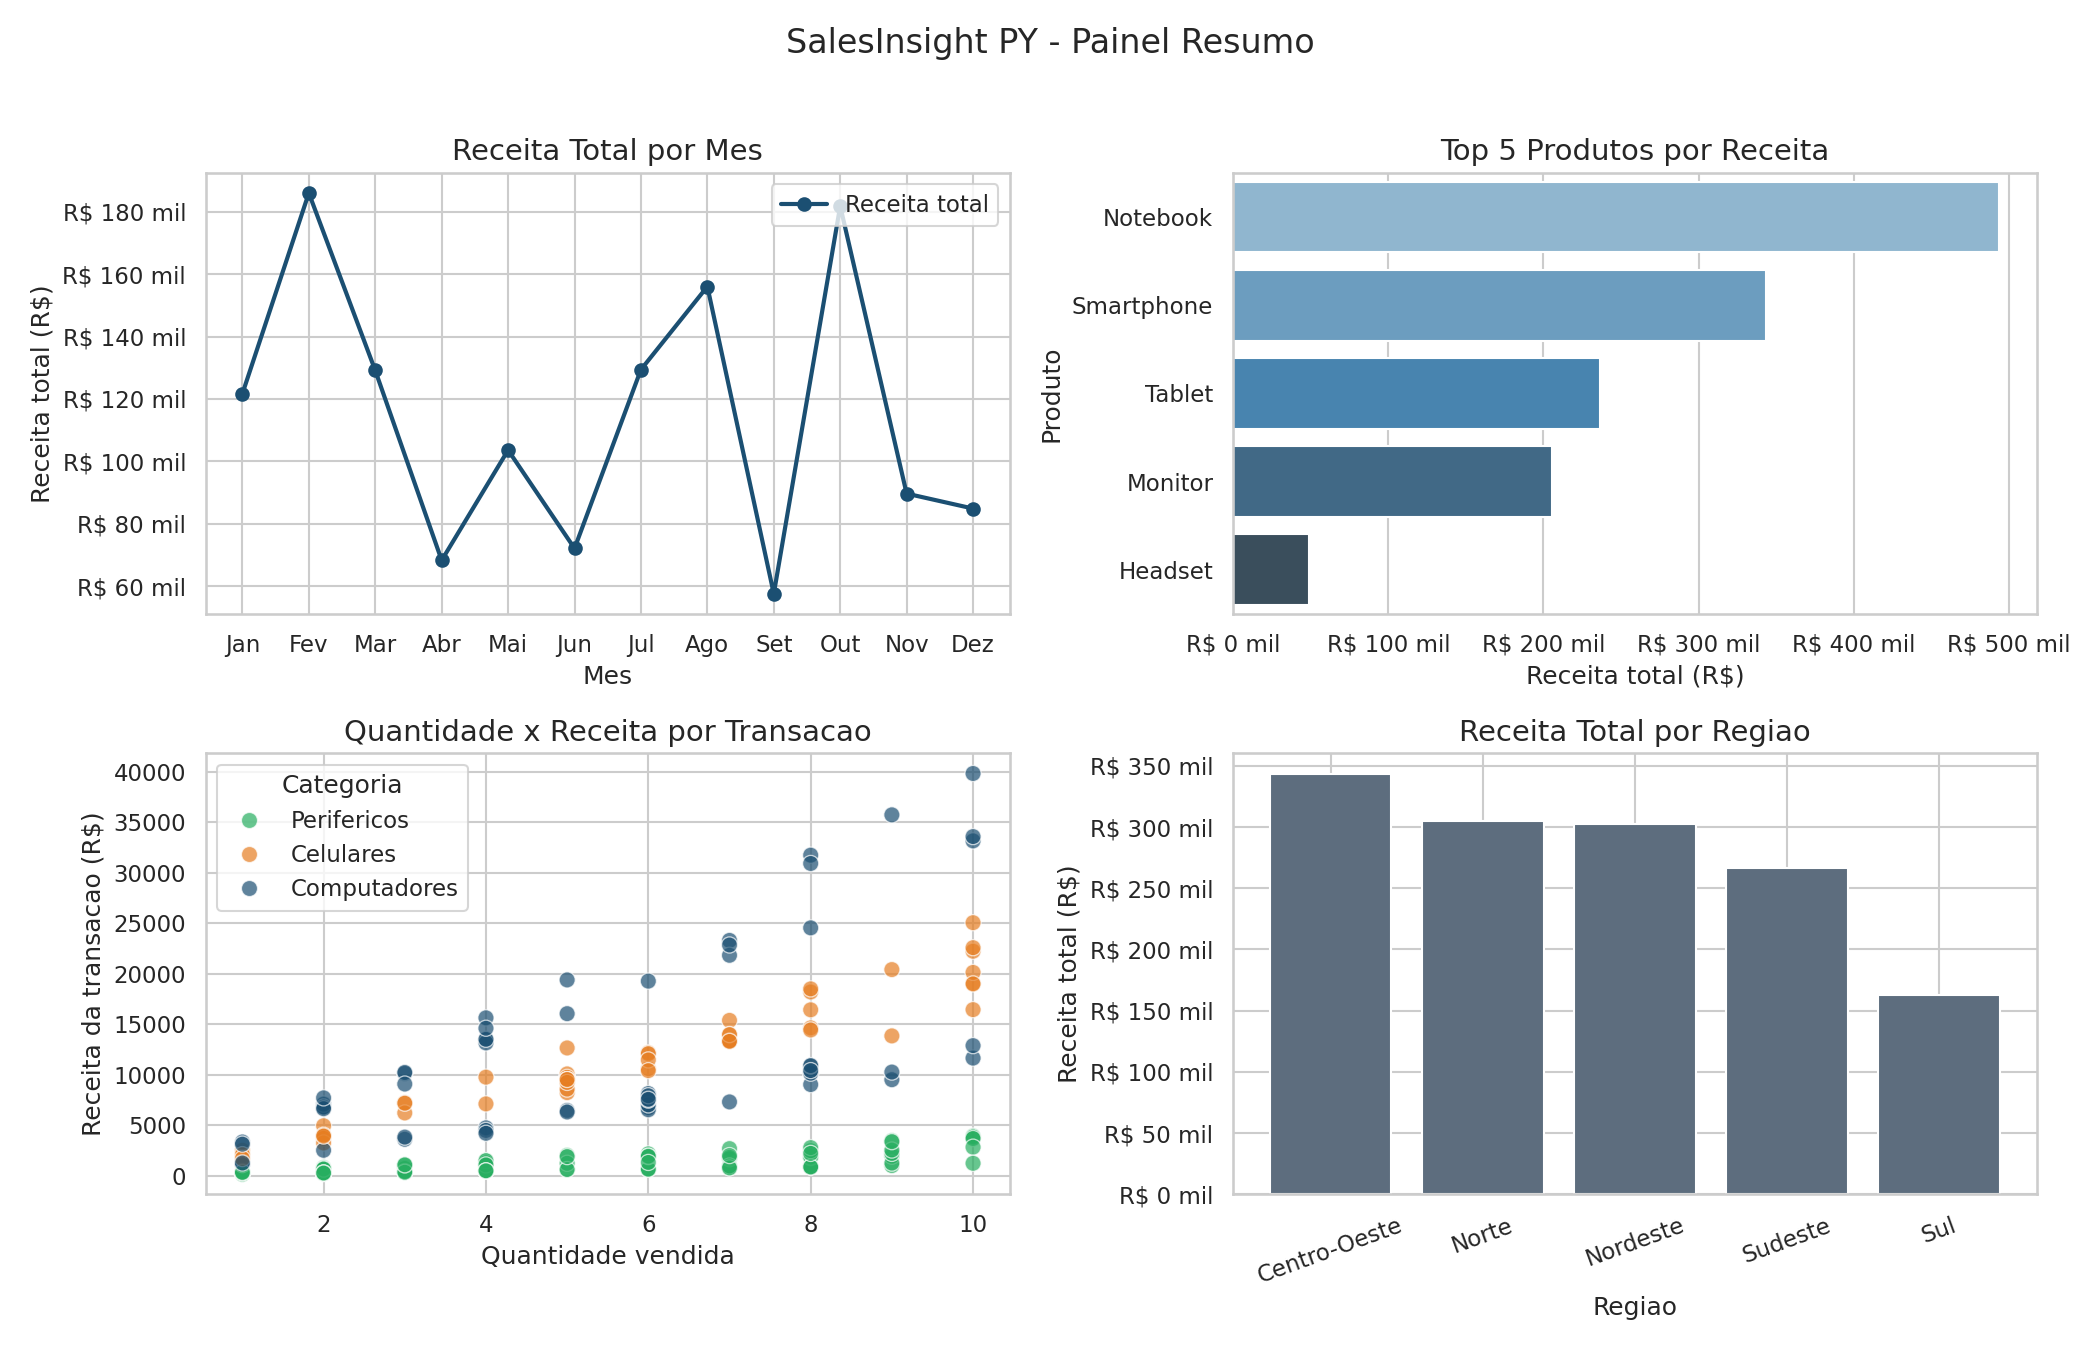

In [27]:
from IPython.display import Image, display
display(Image("outputs/graficos/painel_resumo.png"))